# 03 — CART regression tree implemented from scratch

Model code: `src/scratch_tree.py`.

## Why a tree?
There is no reason for the effect of a disaster to be linear: it is probably negligible for small shocks and sharp beyond a threshold, and may depend on the level of development (a rich country rebuilds faster). A regression tree captures **thresholds and interactions** without specifying them in advance.

## Formulation
The tree partitions $\mathbb{R}^p$ into regions $R_1,\dots,R_M$ and predicts the local mean:
$$\hat f(\mathbf{x})=\sum_{m=1}^{M}c_m\,\mathbb{1}\{\mathbf{x}\in R_m\},\qquad c_m=\frac{1}{|R_m|}\sum_{i:\mathbf{x}_i\in R_m}y_i$$

**Objective (impurity)**: sum of squared errors in each leaf, $\mathrm{SSE}(R)=\sum_{i\in R}(y_i-\bar y_R)^2=\sum y_i^2-\frac{(\sum y_i)^2}{|R|}$.

**Greedy recursive construction.** Finding the globally optimal partition is NP-hard; at each node we choose the split $(j,s)$ that maximizes
$$\Delta(j,s)=\mathrm{SSE}(R)-\mathrm{SSE}(R_{x_j\le s})-\mathrm{SSE}(R_{x_j>s}).$$
Thanks to the cumulative sums of $y$ and $y^2$ after sorting by $x_j$, all splits on one variable are evaluated in $O(n)$ (sorting $O(n\log n)$). Cost per level: $O(p\,n\log n)$.

**Stopping**: maximum depth, `min_samples_leaf` (minimum leaf size), no improving split. These hyperparameters control the bias–variance trade-off and are chosen on the validation set.

In [1]:
import os, sys, time, warnings
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # metrics are allowed
from src import data_prep as dp
from src.plot_style import *
setup()
SEED = 42
np.random.seed(SEED)
pd.set_option("display.precision", 3)
from src.scratch_tree import RegressionTreeScratch, partial_dependence
from src.scratch_linear import LinearRegressionScratch
panel = dp.build_panel()
s = dp.make_splits(panel)
F = s.features

## 1. Check on a toy problem
Noisy step function: a depth-2 tree must recover the three levels and the thresholds 0.3 and 0.7.

x <= 0.299  (n=400)
|   x <= 0.294  (n=121)
|   |   -> ŷ = 0.93  (n=119)
|   x >  0.294
|   |   -> ŷ = 1.29  (n=2)
x >  0.299
|   x <= 0.700  (n=279)
|   |   -> ŷ = 4.01  (n=162)
|   x >  0.700
|   |   -> ŷ = 2.00  (n=117)



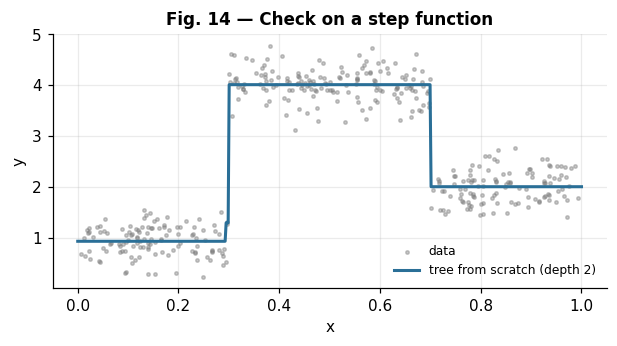

In [2]:
rng = np.random.default_rng(SEED)
x = rng.uniform(0, 1, 400); y = np.where(x < 0.3, 1.0, np.where(x < 0.7, 4.0, 2.0)) + rng.normal(0, 0.3, 400)
toy = RegressionTreeScratch(max_depth=2).fit(x[:, None], y)
print(toy.to_text(["x"], max_depth=2))
grid = np.linspace(0, 1, 500)
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.scatter(x, y, s=5, alpha=0.4, color=C_NEUTRAL, label="data")
ax.plot(grid, toy.predict(grid[:, None]), color=C_SCRATCH, lw=2, label="tree from scratch (depth 2)")
ax.set(title="Fig. 14 — Check on a step function", xlabel="x", ylabel="y"); ax.legend(fontsize=8)
save(fig, "fig14_toy_tree.png"); plt.show()

## 2. Hyperparameter selection (validation)

In [3]:
depths = list(range(1, 13)); leaves = [5, 10, 20, 50, 100, 200]
grid_val = np.zeros((len(leaves), len(depths))); rows = []
for a, L in enumerate(leaves):
    for b, d in enumerate(depths):
        t = RegressionTreeScratch(max_depth=d, min_samples_leaf=L).fit(s.X_train, s.y_train)
        r_tr = mean_squared_error(s.y_train, t.predict(s.X_train)) ** .5
        r_va = mean_squared_error(s.y_val, t.predict(s.X_val)) ** .5
        grid_val[a, b] = r_va; rows.append((d, L, r_tr, r_va, t.n_leaves()))
gs = pd.DataFrame(rows, columns=["max_depth", "min_samples_leaf", "rmse_train", "rmse_val", "n_leaves"])
best = gs.loc[gs.rmse_val.idxmin()]
BEST_D, BEST_L = int(best.max_depth), int(best.min_samples_leaf)
gs.to_csv("../results/tree_grid.csv", index=False)
print(f"Best: max_depth={BEST_D}, min_samples_leaf={BEST_L}, validation RMSE={best.rmse_val:.3f}")

Best: max_depth=8, min_samples_leaf=100, validation RMSE=4.080


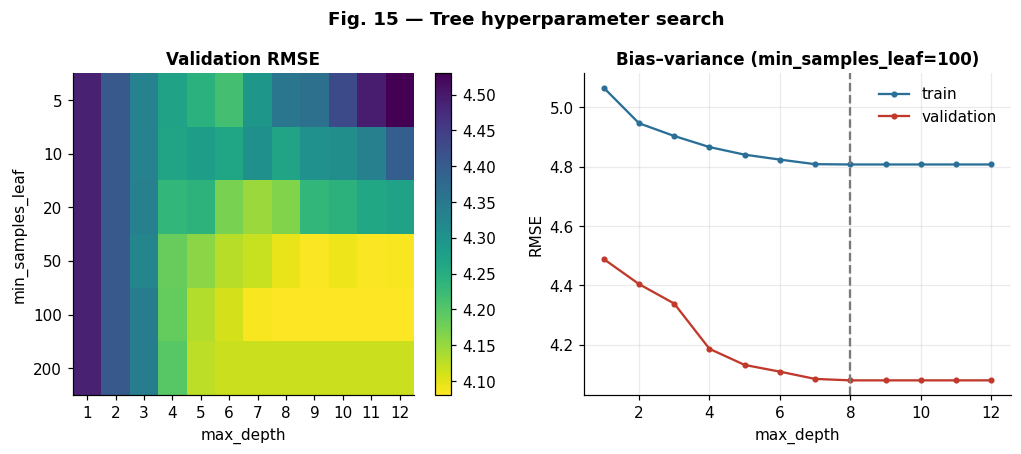

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
im = axes[0].imshow(grid_val, cmap="viridis_r", aspect="auto")
axes[0].set_xticks(range(len(depths))); axes[0].set_xticklabels(depths)
axes[0].set_yticks(range(len(leaves))); axes[0].set_yticklabels(leaves)
axes[0].set(title="Validation RMSE", xlabel="max_depth", ylabel="min_samples_leaf"); axes[0].grid(False)
fig.colorbar(im, ax=axes[0])
sub = gs[gs.min_samples_leaf == BEST_L]
axes[1].plot(sub.max_depth, sub.rmse_train, "o-", ms=3, color=C_SCRATCH, label="train")
axes[1].plot(sub.max_depth, sub.rmse_val, "o-", ms=3, color=C_ACCENT, label="validation")
axes[1].axvline(BEST_D, color=C_NEUTRAL, ls="--")
axes[1].set(title=f"Bias–variance (min_samples_leaf={BEST_L})", xlabel="max_depth", ylabel="RMSE"); axes[1].legend()
fig.suptitle("Fig. 15 — Tree hyperparameter search", fontweight="bold", y=1.03)
save(fig, "fig15_tree_grid.png"); plt.show()

Beyond the optimal depth, the training error keeps falling while the validation error rises again: classic **overfitting**. Leaves that are too small (5–10 observations) amplify the variance.

## 3. Final model and ablation

In [5]:
tree = RegressionTreeScratch(max_depth=BEST_D, min_samples_leaf=BEST_L).fit(s.X_train, s.y_train)
ctrl = [F.index(f) for f in dp.CONTROL_FEATURES]
tree_ctrl = RegressionTreeScratch(max_depth=BEST_D, min_samples_leaf=BEST_L).fit(s.X_train[:, ctrl], s.y_train)
print(f"depth = {tree.depth()}, leaves = {tree.n_leaves()}")
def metrics(y, p): return dict(MAE=mean_absolute_error(y, p), RMSE=mean_squared_error(y, p) ** .5, R2=r2_score(y, p))
rows = []
for split in ["train", "val", "test", "stress"]:
    X, y = getattr(s, f"X_{split}"), getattr(s, f"y_{split}")
    rows.append({"split": split, "model": "Tree (controls only)", **metrics(y, tree_ctrl.predict(X[:, ctrl]))})
    rows.append({"split": split, "model": "Tree (controls + disasters)", **metrics(y, tree.predict(X))})
perf = pd.DataFrame(rows).set_index(["split", "model"]); perf.to_csv("../results/tree_performance.csv"); perf

depth = 8, leaves = 40


MAE   RMSE     R2
split  model                                           
train  Tree (controls only)         3.329  4.810  0.166
       Tree (controls + disasters)  3.324  4.807  0.167
val    Tree (controls only)         2.890  4.084  0.286
       Tree (controls + disasters)  2.888  4.080  0.288
test   Tree (controls only)         2.143  3.316  0.152
       Tree (controls + disasters)  2.138  3.314  0.153
stress Tree (controls only)         6.560  7.937 -1.157
       Tree (controls + disasters)  6.571  7.927 -1.151

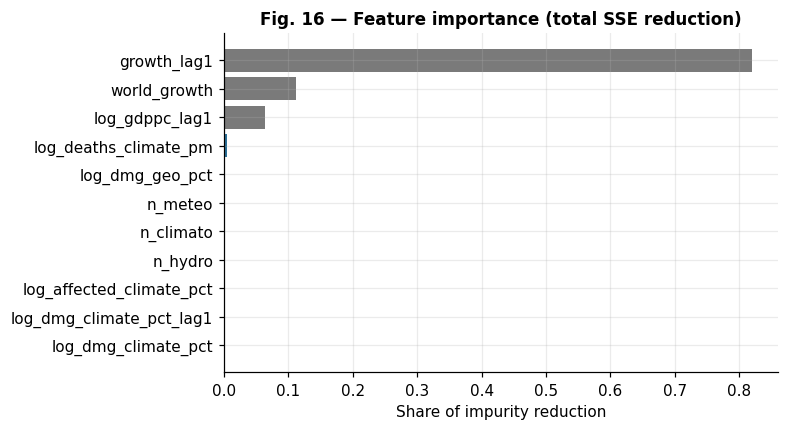

Total share of the disaster variables: 0.5%


In [6]:
imp = pd.Series(tree.feature_importances_, index=F).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.barh(imp.index, imp.values, color=[C_CLIMATE if f in dp.DISASTER_FEATURES else C_NEUTRAL for f in imp.index])
ax.set(title="Fig. 16 — Feature importance (total SSE reduction)", xlabel="Share of impurity reduction")
save(fig, "fig16_tree_importance.png"); plt.show()
print(f"Total share of the disaster variables: {imp[dp.DISASTER_FEATURES].sum():.1%}")

In [7]:
def unscale(j, v): return v * s.std[j] + s.mean[j]
print(tree.to_text(F, max_depth=3, unscale=unscale))

growth_lag1 <= 4.950  (n=5174)
|   growth_lag1 <= -6.442  (n=3234)
|   |   log_gdppc_lag1 <= 6.761  (n=202)
|   |   |   -> ŷ = 0.08  (n=102)
|   |   log_gdppc_lag1 >  6.761
|   |   |   -> ŷ = -1.35  (n=100)
|   growth_lag1 >  -6.442
|   |   growth_lag1 <= 2.420  (n=3032)
|   |   |   -> ŷ = 2.26  (n=1646)
|   |   growth_lag1 >  2.420
|   |   |   -> ŷ = 3.57  (n=1386)
growth_lag1 >  4.950
|   growth_lag1 <= 10.607  (n=1940)
|   |   growth_lag1 <= 7.292  (n=1558)
|   |   |   -> ŷ = 4.51  (n=963)
|   |   growth_lag1 >  7.292
|   |   |   -> ŷ = 5.56  (n=595)
|   growth_lag1 >  10.607
|   |   growth_lag1 <= 16.350  (n=382)
|   |   |   -> ŷ = 7.80  (n=267)
|   |   growth_lag1 >  16.350
|   |   |   -> ŷ = 10.01  (n=115)



## 4. Shape of the effect: partial dependence
We vary the climate damages of year $t$ over a grid, the other variables keeping their observed values (test sample), and average the predictions. We compare the shape learned by the tree (non-linear) and by the linear model.

tree (7, 20): validation RMSE = 4.148, share of disasters in importance = 7.0%


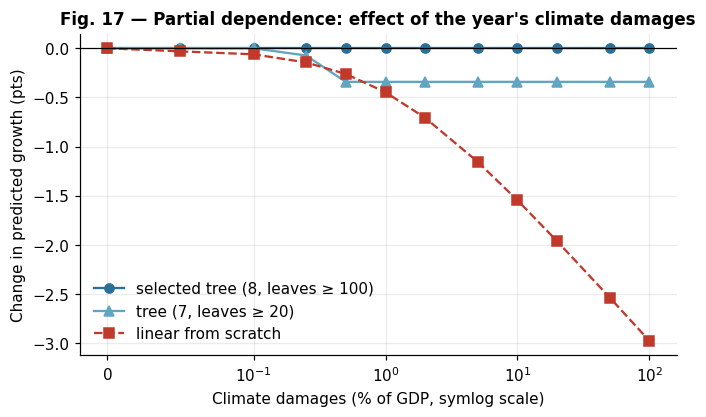

,damages %GDP,selected tree,"tree (7,20)",linear
0,0.00,0.0,0.00,0.00
1,0.05,0.0,0.00,-0.03
2,0.10,0.0,0.00,-0.06
3,0.25,0.0,-0.07,-0.14
4,0.50,0.0,-0.34,-0.26
5,1.00,0.0,-0.34,-0.45
6,2.00,0.0,-0.34,-0.71
7,5.00,0.0,-0.34,-1.15
8,10.00,0.0,-0.34,-1.55
9,20.00,0.0,-0.34,-1.96


In [8]:
lin = LinearRegressionScratch(solver="normal").fit(s.X_train, s.y_train)
j = F.index("log_dmg_climate_pct")
pct = np.array([0, 0.05, 0.1, 0.25, 0.5, 1, 2, 5, 10, 20, 50, 100])
grid = (np.log1p(pct) - s.mean[j]) / s.std[j]
pd_tree = partial_dependence(tree, s.X_test, j, grid)
pd_lin = partial_dependence(lin, s.X_test, j, grid)
# less constrained tree (leaves of 20): more variance, but able to isolate rare shocks
tree20 = RegressionTreeScratch(max_depth=7, min_samples_leaf=20).fit(s.X_train, s.y_train)
pd_t20 = partial_dependence(tree20, s.X_test, j, grid)
print(f"tree (7, 20): validation RMSE = {mean_squared_error(s.y_val, tree20.predict(s.X_val))**.5:.3f}, "
      f"share of disasters in importance = {tree20.feature_importances_[[F.index(f) for f in dp.DISASTER_FEATURES]].sum():.1%}")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(pct, pd_tree - pd_tree[0], "o-", color=C_SCRATCH, label=f"selected tree ({BEST_D}, leaves ≥ {BEST_L})")
ax.plot(pct, pd_t20 - pd_t20[0], "^-", color="#61a5c2", label="tree (7, leaves ≥ 20)")
ax.plot(pct, pd_lin - pd_lin[0], "s--", color=C_ACCENT, label="linear from scratch")
ax.set_xscale("symlog", linthresh=0.1); ax.axhline(0, color="k", lw=0.8)
ax.set(title="Fig. 17 — Partial dependence: effect of the year's climate damages",
       xlabel="Climate damages (% of GDP, symlog scale)", ylabel="Change in predicted growth (pts)")
ax.legend(); save(fig, "fig17_partial_dependence.png"); plt.show()
pd.DataFrame({"damages %GDP": pct, "selected tree": pd_tree - pd_tree[0], "tree (7,20)": pd_t20 - pd_t20[0], "linear": pd_lin - pd_lin[0]}).round(2)

**An important (negative) result for the tree.** The tree selected on validation (leaves ≥ 100) **hardly uses the disasters at all**: its partial dependence is flat and the ablation changes almost nothing. This is not a bug but a structural limitation: only 3.7 % of country-years suffer a shock > 1 % of GDP. A 100-observation leaf cannot isolate these rare cases, and the SSE reduction they bring is dwarfed by that of growth persistence (`growth_lag1`, ~60 % of the importance). A less constrained tree (leaves ≥ 20) does use them and finds a step-shaped negative effect for large shocks, but it generalizes worse (higher validation RMSE).

The linear model, on the other hand, **pools the information** across all observations through a single coefficient: it is statistically more efficient at detecting a moderate average effect carried by a rare variable. That is why it beats the tree on the test set and is the reference model for answering the question.

## 5. Computational cost

In [9]:
rng = np.random.default_rng(SEED); rows = []
for n in [500, 1000, 2000, 3500, 5174]:
    idx = rng.choice(len(s.y_train), n, replace=False)
    t = time.perf_counter(); RegressionTreeScratch(max_depth=BEST_D, min_samples_leaf=BEST_L).fit(s.X_train[idx], s.y_train[idx])
    rows.append((n, time.perf_counter() - t))
tim = pd.DataFrame(rows, columns=["n", "time (s)"]); tim

,n,time (s)
0,500,0.005
1,1000,0.009
2,2000,0.018
3,3500,0.042
4,5174,0.065
